Hold features: 11
DD features: 10
UD features: 10

Fingerprint shape: (51, 10)


,subject,avg_hold_time,avg_dd_time,avg_ud_time,hold_time_std,dd_time_std,ud_time_std,min_hold_time,max_hold_time,typing_speed
0,s002,0.094042,0.235871,0.140695,0.019191,0.097550,0.095686,0.041736,0.184455,3.031099
1,s003,0.126159,0.199036,0.070182,0.026394,0.093689,0.099425,0.046045,0.222564,3.075083
2,s004,0.100341,0.212618,0.109796,0.015726,0.091414,0.092072,0.041955,0.154682,3.195314
3,s005,0.103160,0.292413,0.188146,0.015580,0.102532,0.103843,0.035809,0.165700,2.527972
4,s007,0.091494,0.171067,0.078812,0.016187,0.071972,0.074026,0.033536,0.144709,3.808636



Missing values:
subject          0
avg_hold_time    0
avg_dd_time      0
avg_ud_time      0
hold_time_std    0
dd_time_std      0
ud_time_std      0
min_hold_time    0
max_hold_time    0
typing_speed     0
dtype: int64

Fingerprint statistics:


,avg_hold_time,avg_dd_time,avg_ud_time,hold_time_std,dd_time_std,ud_time_std,min_hold_time,max_hold_time,typing_speed
count,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000
mean,0.090096,0.249192,0.158917,0.016054,0.125761,0.126156,0.033355,0.155745,3.109474
std,0.019214,0.087364,0.091170,0.005078,0.074008,0.073308,0.008910,0.049662,0.667568
min,0.046291,0.135938,0.040116,0.006748,0.048849,0.051260,0.014300,0.072955,1.667357
25%,0.080652,0.190040,0.101890,0.012376,0.082692,0.083060,0.026545,0.133645,2.757940
50%,0.090543,0.221496,0.133872,0.015732,0.104907,0.103912,0.033827,0.143945,3.152519
75%,0.098446,0.276032,0.192414,0.018951,0.151472,0.149117,0.039541,0.169641,3.570930
max,0.143135,0.539664,0.493556,0.030232,0.521192,0.515202,0.054518,0.344764,4.277250


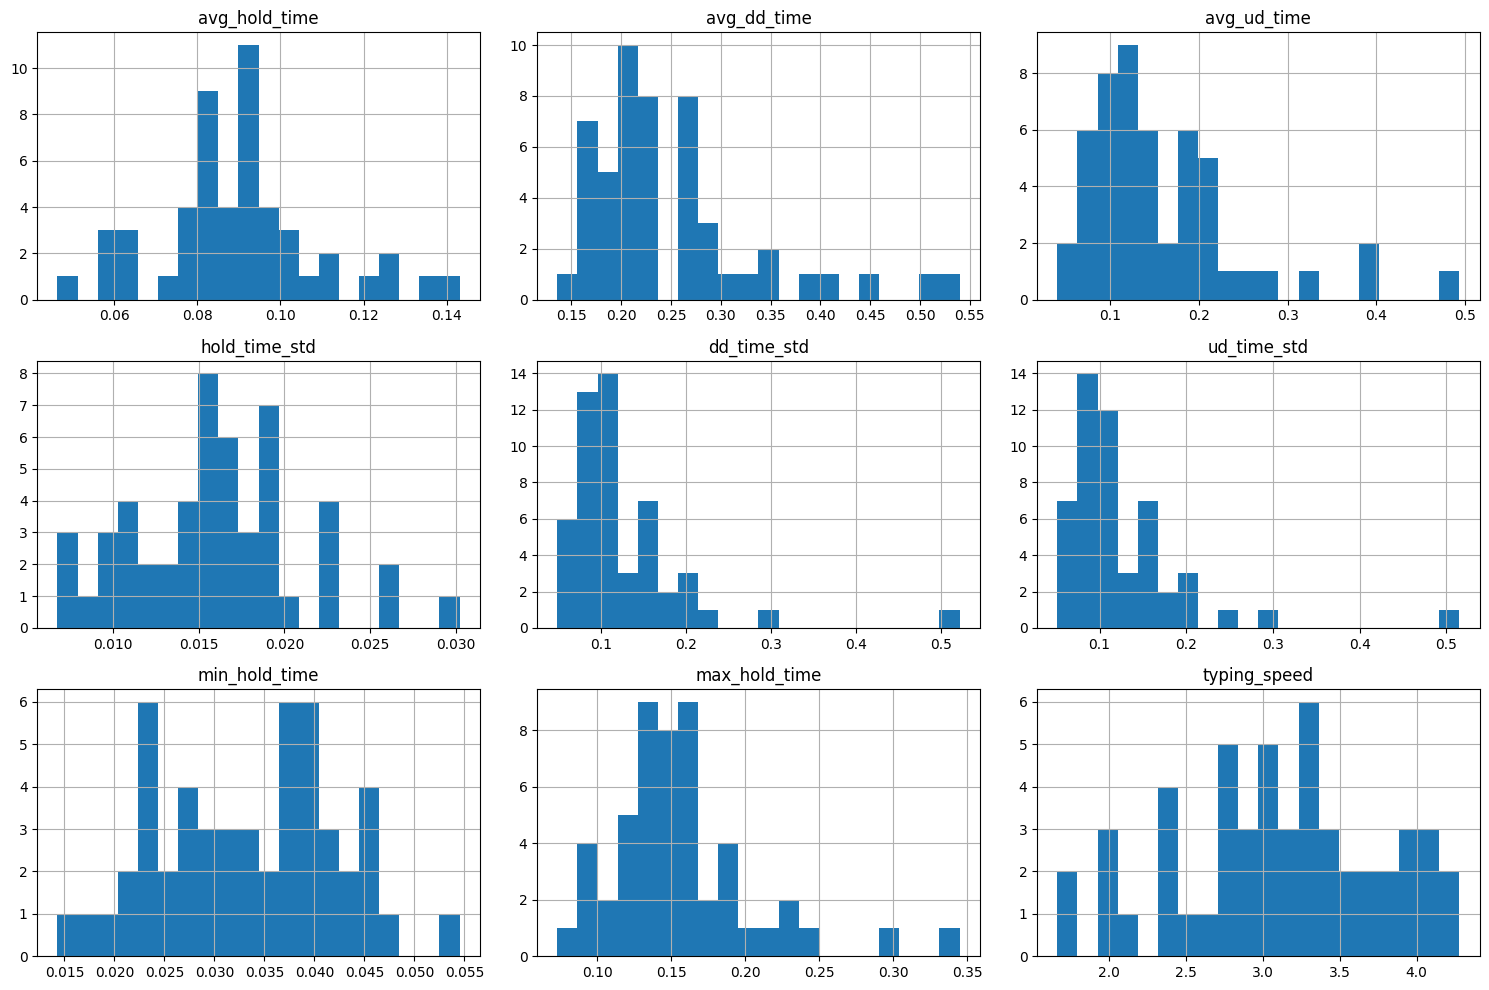

,subject,avg_hold_time,avg_dd_time,avg_ud_time,hold_time_std,dd_time_std,ud_time_std,min_hold_time,max_hold_time,typing_speed
0,s002,0.094042,0.235871,0.140695,0.019191,0.097550,0.095686,0.041736,0.184455,3.031099
1,s003,0.126159,0.199036,0.070182,0.026394,0.093689,0.099425,0.046045,0.222564,3.075083
2,s004,0.100341,0.212618,0.109796,0.015726,0.091414,0.092072,0.041955,0.154682,3.195314
3,s005,0.103160,0.292413,0.188146,0.015580,0.102532,0.103843,0.035809,0.165700,2.527972
4,s007,0.091494,0.171067,0.078812,0.016187,0.071972,0.074026,0.033536,0.144709,3.808636



Fingerprint dataset saved successfully.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dataset
df = pd.read_csv(r"E:\Digital_Behavior_Fingerprint\data\raw\DSL-StrongPasswordData.csv")

# 2. Separate identifiers
id_columns = ["subject", "sessionIndex", "rep"]

# 3. Identify behavioural features
behaviour_features = [col for col in df.columns if col not in id_columns]

# 4. Group features
hold_features = [col for col in behaviour_features if col.startswith("H.")]
dd_features = [col for col in behaviour_features if col.startswith("DD.")]
ud_features = [col for col in behaviour_features if col.startswith("UD.")]

print("Hold features:", len(hold_features))
print("DD features:", len(dd_features))
print("UD features:", len(ud_features))

# 5. Calculate subject-level statistics
mean_features = df.groupby("subject")[behaviour_features].mean()
median_features = df.groupby("subject")[behaviour_features].median()
std_features = df.groupby("subject")[behaviour_features].std()
min_features = df.groupby("subject")[behaviour_features].min()
max_features = df.groupby("subject")[behaviour_features].max()

# 6. Create fingerprint features
fingerprint = pd.DataFrame(index=df["subject"].unique())

# Average timing behaviour
fingerprint["avg_hold_time"] = df.groupby("subject")[hold_features].mean().mean(axis=1)
fingerprint["avg_dd_time"] = df.groupby("subject")[dd_features].mean().mean(axis=1)
fingerprint["avg_ud_time"] = df.groupby("subject")[ud_features].mean().mean(axis=1)

# Timing variability
fingerprint["hold_time_std"] = df.groupby("subject")[hold_features].std().mean(axis=1)
fingerprint["dd_time_std"] = df.groupby("subject")[dd_features].std().mean(axis=1)
fingerprint["ud_time_std"] = df.groupby("subject")[ud_features].std().mean(axis=1)

# Minimum and maximum timing
fingerprint["min_hold_time"] = df.groupby("subject")[hold_features].min().mean(axis=1)
fingerprint["max_hold_time"] = df.groupby("subject")[hold_features].max().mean(axis=1)

# 7. Calculate approximate typing speed
fingerprint["typing_speed"] = 1 / (
    fingerprint["avg_hold_time"] + fingerprint["avg_dd_time"]
)

# 8. Add subject identifier
fingerprint.insert(0, "subject", fingerprint.index)

# 9. Reset index
fingerprint = fingerprint.reset_index(drop=True)

# 10. Display fingerprint
print("\nFingerprint shape:", fingerprint.shape)
display(fingerprint.head())

# 11. Check missing values
print("\nMissing values:")
print(fingerprint.isnull().sum())

# 12. Check statistics
print("\nFingerprint statistics:")
display(fingerprint.describe())

# 13. Visualize fingerprint features
fingerprint_features = fingerprint.drop(columns=["subject"])

fingerprint_features.hist(
    figsize=(15, 10),
    bins=20
)

plt.tight_layout()
plt.show()

# 14. Compare a few subjects
sample_subjects = fingerprint["subject"].head(5)

comparison = fingerprint[
    fingerprint["subject"].isin(sample_subjects)
]

display(comparison)

# 15. Save processed fingerprint dataset
fingerprint.to_csv(
    "../data/processed/keystroke_fingerprints.csv",
    index=False
)

print("\nFingerprint dataset saved successfully.")